In [ ]:
!pip install shap transformers

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 540.1/540.1 kB 5.0 MB/s eta 0:00:00


In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import shap
import torch

In [ ]:
# Load the tokenizer and model
tokenizer = AutoTokenizer.from_pretrained("rafalposwiata/roberta-large-depression")
model = AutoModelForSequenceClassification.from_pretrained("rafalposwiata/roberta-large-depression")

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/352 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/904 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

In [ ]:
# Define a function that takes a list of texts and returns model outputs
def model_predict(texts):
    inputs = tokenizer(texts, padding=True, truncation=True, return_tensors="pt")
    with torch.no_grad():
        outputs = model(**inputs)
    return outputs.logits

In [ ]:
# Function to map logits to labels
def predict_labels(texts):
    logits = model_predict(texts)
    predicted_classes = torch.argmax(logits, dim=1).tolist()
    index_to_label = {0: "severe", 1: "moderate", 2: "not depression"}
    predicted_labels = [index_to_label[cls] for cls in predicted_classes]
    return predicted_labels

In [ ]:
# Sample texts for explanation
sample_texts = [
    "I want to kill myself.",
    "I feel so hopeless and worthless.",
    "I'm feeling a bit down lately, but it's manageable.",
    "I'm okay, just a bit stressed out.",
    "I don't have any symptoms of depression.",
    "Life is good and I'm feeling happy."
]

In [ ]:
# Predict the classes for the sample texts
predicted_labels = predict_labels(sample_texts)

# Print the predicted classes for each text
for text, label in zip(sample_texts, predicted_labels):
    print(f"Text: {text}\nPredicted label: {label}\n")

Text: I want to kill myself.
Predicted label: moderate

Text: I feel so hopeless and worthless.
Predicted label: not depression

Text: I'm feeling a bit down lately, but it's manageable.
Predicted label: not depression

Text: I'm okay, just a bit stressed out.
Predicted label: not depression

Text: I don't have any symptoms of depression.
Predicted label: not depression

Text: Life is good and I'm feeling happy.
Predicted label: not depression



In [ ]:
# build a pipeline object to do predictions
from transformers import pipeline
pred = pipeline(
    "text-classification",
    model=model,
    tokenizer=tokenizer,
    device='cpu',
    return_all_scores=True,
)

/usr/local/lib/python3.10/dist-packages/transformers/pipelines/text_classification.py:104: UserWarning: `return_all_scores` is now deprecated,  if want a similar functionality use `top_k=None` instead of `return_all_scores=True` or `top_k=1` instead of `return_all_scores=False`.
  warnings.warn(


In [ ]:
explainer = shap.Explainer(pred)

In [ ]:
# Sample text for explanation
text = ["I want to kill myself."]

In [ ]:
shap_values = explainer(text)

  0%|          | 0/56 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:28, 28.61s/it]               


In [ ]:
import numpy as np
np.shape(shap_values)

(1, 8, 3)

In [ ]:
shap.plots.text(shap_values)

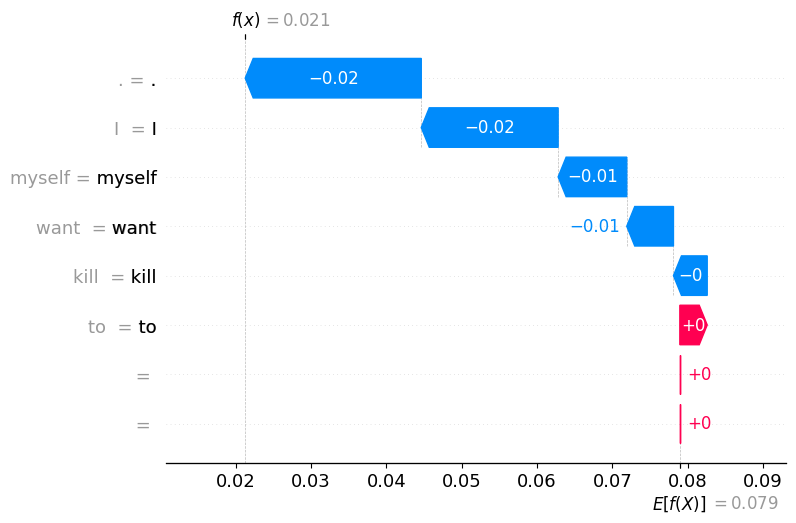

In [ ]:
shap.plots.waterfall(shap_values[0, :, 0])

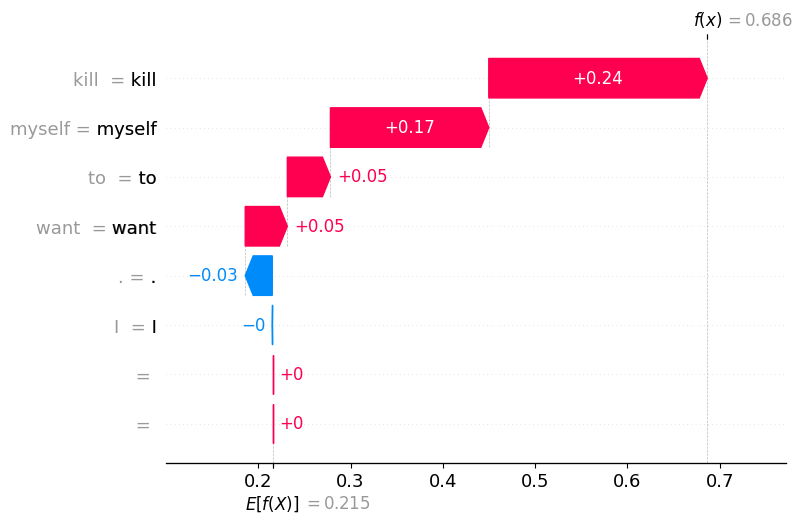

In [ ]:
shap.plots.waterfall(shap_values[0, :, 1])

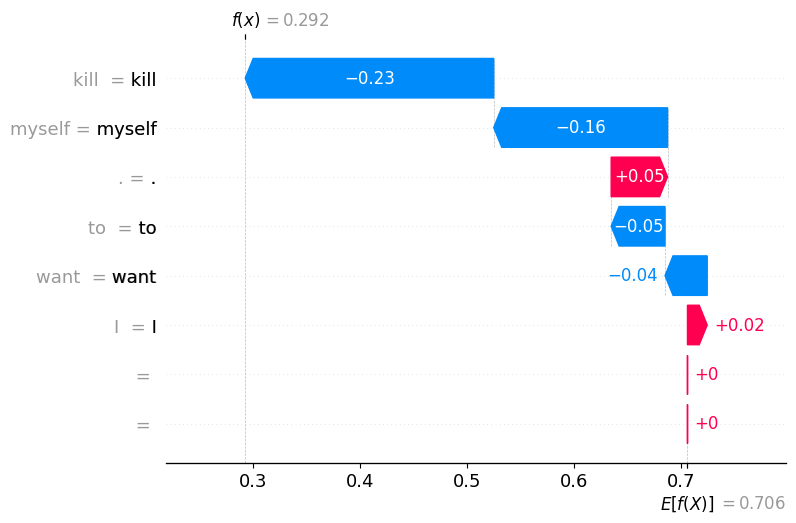

In [ ]:
shap.plots.waterfall(shap_values[0, :, 2])